In [1]:
import tensorflow.keras.layers as Layers
import tensorflow.keras.activations as Actications
import tensorflow.keras.models as Models
import tensorflow.keras.optimizers as Optimizer
import tensorflow.keras.metrics as Metrics
import tensorflow.keras.utils as Utils
#from keras.utils.vis_utils import model_to_dot
import os
import matplotlib.pyplot as plot
import cv2
import numpy as np
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix as CM
from random import randint
#from IPython.display import SVG
import matplotlib.gridspec as gridspec
from tensorflow.keras.models import model_from_json

In [2]:
def get_images(directory):
    Names = []
    Images = []
    Labels = []  # 0 for Building , 1 for forest, 2 for glacier, 3 for mountain, 4 for Sea , 5 for Street
    label = 0
    
    for labels in os.listdir(directory): #Main Directory where each class label is present as folder name.
        if labels == 'head': #Folder contain Glacier Images get the '2' class label.
            label = 0
        elif labels == 'body':
            label = 1
        
        for image_file in os.listdir(directory+'/'+labels): #Extracting the file name of the image from Class Label folder
            image = cv2.imread(directory+'/'+labels+'/'+image_file) #Reading the image (OpenCV)
            image = cv2.resize(image,(150,150)) #Resize the image, Some images are different sizes. (Resizing is very Important)
            Names.append(image_file)
            Images.append(image)
            Labels.append(label)
    
    return shuffle(Images,Labels,random_state=817328462) #Shuffle the dataset you just prepared.

def get_classlabel(class_code):
    labels = {0:'head', 1:'body'}
    
    return labels[class_code]

In [3]:
#Images, Labels = get_images('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/Train_fantoms_NN') #Extract the training images from the folders.
#Images, Labels = get_images('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/Train_data_startend/data_for_NN') #Extract the training images from the folders.
Images, Labels = get_images('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/Train_data_startend/data_for_NN_1176') #Extract the training images from the folders.

Images = np.array(Images) #converting the list of images to numpy array.
Labels = np.array(Labels)

In [4]:
print("Shape of Images:",Images.shape)
print("Shape of Labels:",Labels.shape)

Shape of Images: (2025, 150, 150, 3)
Shape of Labels: (2025,)


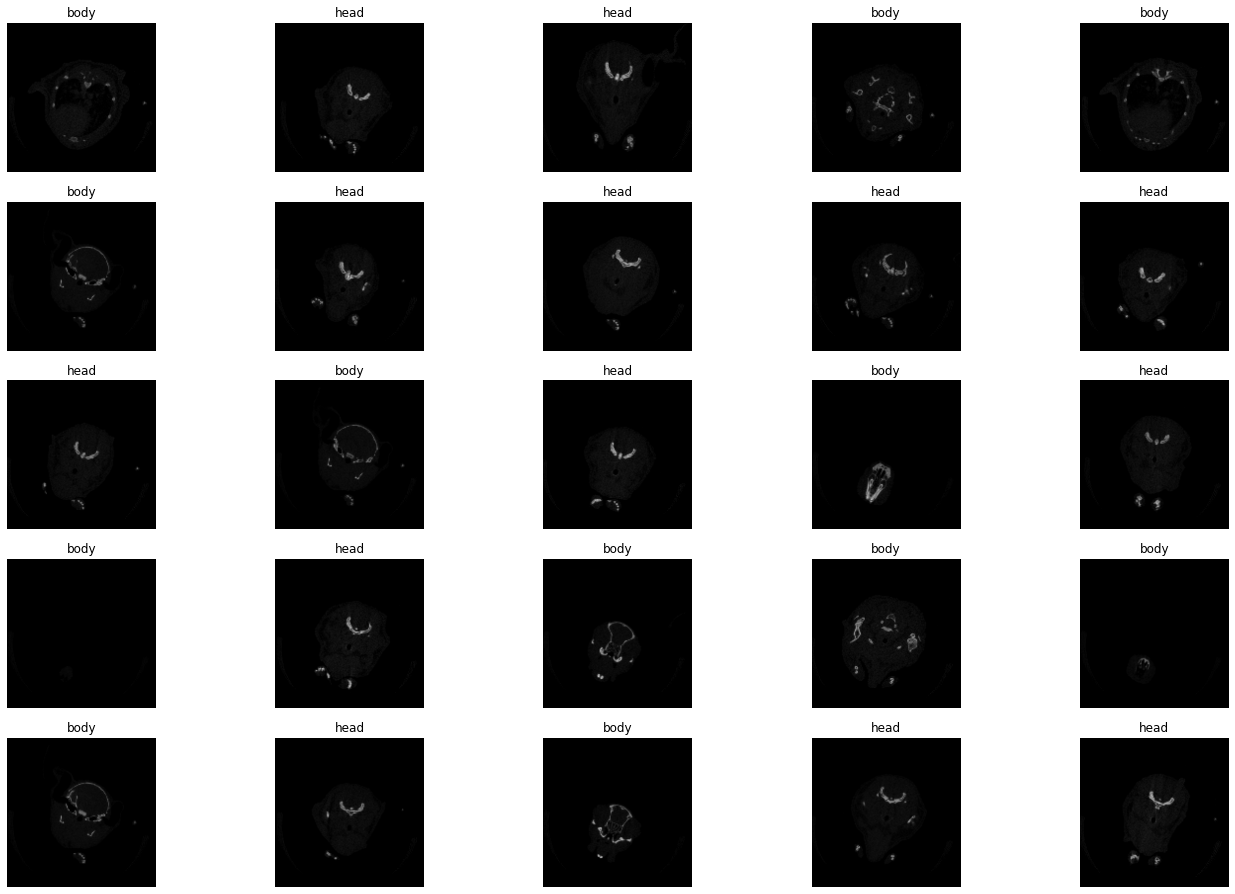

In [5]:
f,ax = plot.subplots(5,5) 
f.subplots_adjust(0,0,3,3)
for i in range(0,5,1):
    for j in range(0,5,1):
        rnd_number = randint(0,len(Images))
        ax[i,j].imshow(Images[rnd_number])
        ax[i,j].set_title(get_classlabel(Labels[rnd_number]))
        ax[i,j].axis('off')

In [12]:
model = Models.Sequential()

model.add(Layers.Conv2D(150,kernel_size=(3,3),activation='relu',input_shape=(150,150,3)))
model.add(Layers.Conv2D(130,kernel_size=(3,3),activation='relu'))
model.add(Layers.MaxPool2D(5,5))
model.add(Layers.Conv2D(150,kernel_size=(3,3),activation='relu'))
model.add(Layers.Conv2D(110,kernel_size=(3,3),activation='relu'))
model.add(Layers.Conv2D(70,kernel_size=(3,3),activation='relu'))
model.add(Layers.Conv2D(20,kernel_size=(3,3),activation='relu'))
model.add(Layers.MaxPool2D(5,5))
model.add(Layers.Flatten())
model.add(Layers.Dense(150,activation='relu'))
model.add(Layers.Dense(70,activation='relu'))
model.add(Layers.Dense(20,activation='relu'))
model.add(Layers.Dropout(rate=0.5))
model.add(Layers.Dense(2,activation='sigmoid'))

model.compile(optimizer=Optimizer.Adam(learning_rate=0.0001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

model.summary()
#IPython.display.display_svg(model_to_dot(model).create(prog='dot', format='svg'))
Utils.plot_model(model,to_file='model.png',show_shapes=True)

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_6 (Conv2D)            (None, 148, 148, 150)     4200      
_________________________________________________________________
conv2d_7 (Conv2D)            (None, 146, 146, 130)     175630    
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 29, 29, 130)       0         
_________________________________________________________________
conv2d_8 (Conv2D)            (None, 27, 27, 150)       175650    
_________________________________________________________________
conv2d_9 (Conv2D)            (None, 25, 25, 110)       148610    
_________________________________________________________________
conv2d_10 (Conv2D)           (None, 23, 23, 70)        69370     
_________________________________________________________________
conv2d_11 (Conv2D)           (None, 21, 21, 20)       

In [13]:
trained = model.fit(Images,Labels,epochs=2,validation_split=0.30)

Epoch 1/2
45/45 [==============================] - 149s 3s/step - loss: 0.6345 - accuracy: 0.6874 - val_loss: 0.2169 - val_accuracy: 0.9720
Epoch 2/2
45/45 [==============================] - 146s 3s/step - loss: 0.1875 - accuracy: 0.9372 - val_loss: 0.0451 - val_accuracy: 0.9951


In [14]:
model.save_weights("NN_model_classify_head_1176_retrained.h5")

In [15]:
model_json = model.to_json()
with open("NN_model_classify_head_1176_retrained.json", "w") as json_file:
    json_file.write(model_json)

In [16]:
from tensorflow.keras.models import model_from_json
json_file = open('NN_model_classify_head_1176_retrained.json', 'r')
loaded_model_json = json_file.read()
json_file.close()
loaded_model = model_from_json(loaded_model_json)
loaded_model.load_weights("NN_model_classify_head_1176_retrained.h5")

In [17]:
loaded_model

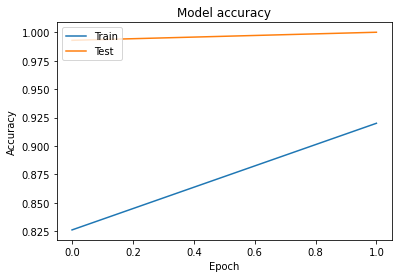

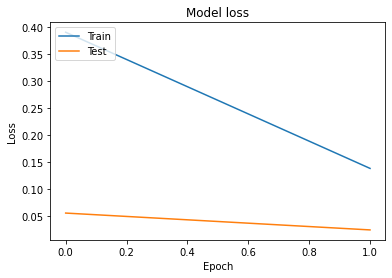

In [26]:
plot.plot(trained.history['accuracy'])
plot.plot(trained.history['val_accuracy'])
plot.title('Model accuracy')
plot.ylabel('Accuracy')
plot.xlabel('Epoch')
plot.legend(['Train', 'Test'], loc='upper left')
plot.show()

plot.plot(trained.history['loss'])
plot.plot(trained.history['val_loss'])
plot.title('Model loss')
plot.ylabel('Loss')
plot.xlabel('Epoch')
plot.legend(['Train', 'Test'], loc='upper left')
plot.show()

In [13]:
 
def get_image_for_pred(directory):
    Names = []
    Images = []
       
    for image_file in sorted(os.listdir(directory))[0:1000]: #Extracting the file name of the image from Class Label folder
        image = cv2.imread(directory+'/'+image_file) #Reading the image (OpenCV)
        #print(image)
        image = cv2.resize(image,(150,150)) #Resize the image, Some images are different sizes. (Resizing is very Important)
        Names.append(image_file)
        #print(Names)
        Images.append(image)

    
    return shuffle(Images,Names) #Shuffle the dataset you just prepared.

In [14]:
pred_images, names = get_image_for_pred('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/Train_data_startend/Babam1_F_E64-F5694_Rec')
pred_images = np.array(pred_images)
pred_images.shape

(1000, 150, 150, 3)

In [67]:
names_pred = []
values_pred =[]
for i in range(0,len(pred_images)):
    rnd_number = i
    pred_image = np.array([pred_images[rnd_number]])
    pred_class = get_classlabel(np.argmax(model.predict(pred_image)[0],axis=-1))
    pred_prob = model.predict(pred_image).reshape(2)
    index_max= np.where(pred_prob == max(pred_prob))
    names_pred.append(names[rnd_number])
    values_pred.append(pred_prob[0])

    print(names[rnd_number],pred_prob[0],pred_class)

Babam1_F_E64-F5694__IR_rec0954.bmp 0.6910217 head
Babam1_F_E64-F5694__IR_rec1009.bmp 0.045717865 body
Babam1_F_E64-F5694__IR_rec0158.bmp 0.0012181103 body
Babam1_F_E64-F5694__IR_rec0121.bmp 0.25642818 body
Babam1_F_E64-F5694__IR_rec0332.bmp 2.6813547e-08 body
Babam1_F_E64-F5694__IR_rec0608.bmp 0.6715375 head
Babam1_F_E64-F5694__IR_rec0070.bmp 0.46371618 body
Babam1_F_E64-F5694__IR_rec0704.bmp 0.18790713 head
Babam1_F_E64-F5694__IR_rec0855.bmp 1.0204391e-06 body
Babam1_F_E64-F5694__IR_rec0762.bmp 7.6904355e-05 body
Babam1_F_E64-F5694__IR_rec0379.bmp 5.714588e-09 body
Babam1_F_E64-F5694__IR_rec0999.bmp 0.050704867 body
Babam1_F_E64-F5694__IR_rec0406.bmp 3.6067221e-10 body
Babam1_F_E64-F5694__IR_rec0844.bmp 5.8277874e-07 body
Babam1_F_E64-F5694__IR_rec0213.bmp 3.3180535e-05 body
Babam1_F_E64-F5694__IR_rec0713.bmp 0.050495923 head
Babam1_F_E64-F5694__IR_rec0901.bmp 0.000109898596 body
Babam1_F_E64-F5694__IR_rec0425.bmp 1.0233413e-06 body
Babam1_F_E64-F5694__IR_rec0793.bmp 5.5658587e-05 bod

In [68]:
max_value=max(values_pred)
print(max_value)
index_max=values_pred.index(max_value)
print(index_max)
names_pred[index_max]

0.9831553
914


'Babam1_F_E64-F5694__IR_rec0644.bmp'